# PART 1 — Environment Setup (10pts)

**1.1 Environment Setup**
Create a dedicated Python environment and verify all required libraries are correctly installed.

In [1]:
# Run this cell to verify your environment
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn import __version__ as sk_version
print(f'NumPy:       {np.__version__}')
print(f'Pandas:      {pd.__version__}')
print(f'Scikit-learn:{sk_version}')
print('All libraries imported successfully!')

NumPy:       2.4.6
Pandas:      3.0.6
Scikit-learn:1.9.1
All libraries imported successfully!


# PART 2 — Exploratory Data Analysis (15 pts)

**2.1 Dataset Overview**

Load the full California Housing dataset into a Pandas DataFrame and provide a structured overview. (3 pts)

In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame  # Contains both features and target

# Display shape, column types, missing values, and descriptive statistics
print('Shape:', df.shape)
print('\nColumn types:')
print(df.dtypes)
print('\nMissing values:')
print(df.isnull().sum())
df.describe()

Shape: (20640, 9)

Column types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


**Answers:**

1. The dataset contains 20,640 instances, 8 input features, and 1 target variable.
2. There are no missing values in any feature.
3. MedInc ranges from 0.4999 to 15.0001.

**2.2 Visualizations**

Create the following four plots. For each, write two sentences interpreting the key insight. (8 pts — 2 pts each)

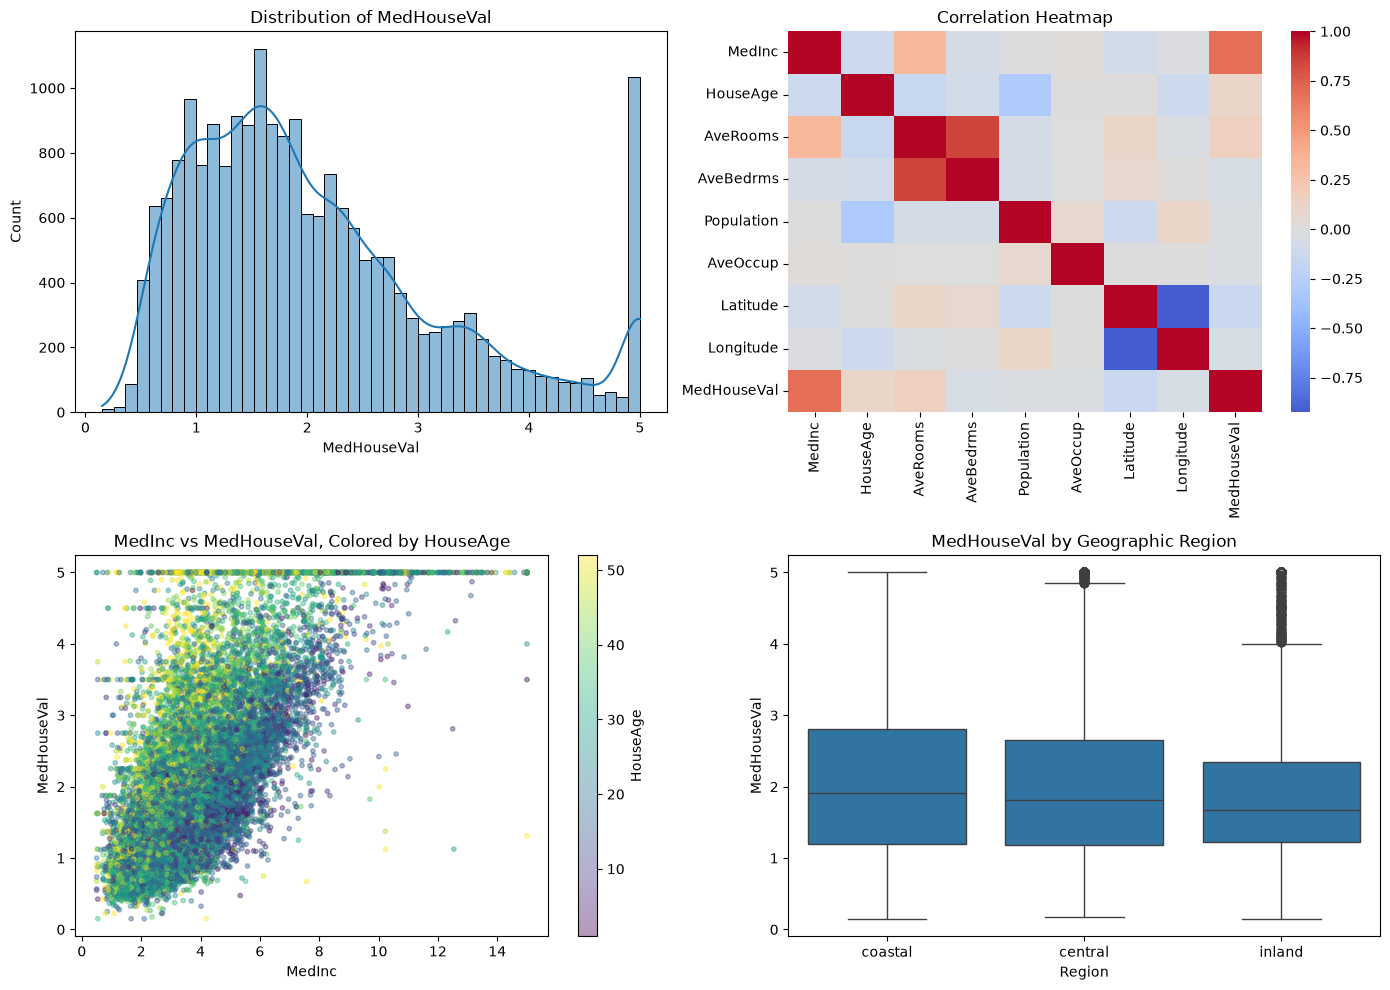

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1: Distribution of target
sns.histplot(df['MedHouseVal'], kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Distribution of MedHouseVal')
axes[0, 0].set_xlabel('MedHouseVal')

# 2: Correlation heatmap
sns.heatmap(df.corr(numeric_only=True), cmap='coolwarm', center=0, ax=axes[0, 1])
axes[0, 1].set_title('Correlation Heatmap')

# 3: Scatter MedInc vs MedHouseVal
scatter = axes[1, 0].scatter(df['MedInc'], df['MedHouseVal'], c=df['HouseAge'], cmap='viridis', alpha=0.4, s=10)
axes[1, 0].set_title('MedInc vs MedHouseVal, Colored by HouseAge')
axes[1, 0].set_xlabel('MedInc')
axes[1, 0].set_ylabel('MedHouseVal')
fig.colorbar(scatter, ax=axes[1, 0], label='HouseAge')

# 4: Box plots by region
region = pd.Series('central', index=df.index)
region[df['Longitude'] < -121] = 'coastal'
region[df['Longitude'] > -118] = 'inland'
plot_df = df.assign(Region=region)
sns.boxplot(data=plot_df, x='Region', y='MedHouseVal', order=['coastal', 'central', 'inland'], ax=axes[1, 1])
axes[1, 1].set_title('MedHouseVal by Geographic Region')
axes[1, 1].set_xlabel('Region')
axes[1, 1].set_ylabel('MedHouseVal')

plt.tight_layout()
plt.savefig('eda_plots.png', dpi=120)
plt.show()

**Interpretation / Insights:**

1. **Distribution of MedHouseVal:** Most median house values are concentrated between approximately 1.0 and 3.0. The large spike at 5.0 indicates that the target variable is capped at its upper limit.

2. **Correlation heatmap:** MedInc has the strongest positive correlation with MedHouseVal. Latitude and longitude also show relationships with house value, indicating that geographic location influences prices.

3. **MedInc vs. MedHouseVal:** MedHouseVal generally increases as MedInc increases. HouseAge does not create a clearly separated pattern in this relationship.

4. **MedHouseVal by geographic region:** The coastal region has a higher median house value than the central and inland regions. The inland region generally has the lowest house values.

**2.3 Feature Correlation Analysis**

Identify the three features most correlated with MedHouseVal. Justify why these features might have predictive power based on domain knowledge. (4 pts)

In [4]:
# Compute and sort absolute correlations with target
correlations = df.corr(numeric_only=True)['MedHouseVal'].drop('MedHouseVal').abs().sort_values(ascending=False)
print(correlations.head(5))

MedInc       0.688075
AveRooms     0.151948
Latitude     0.144160
HouseAge     0.105623
AveBedrms    0.046701
Name: MedHouseVal, dtype: float64


**Top 3 features & justification:**

1. **MedInc:** Areas with higher median income generally have greater purchasing power and demand for more expensive housing, so house values tend to be higher.
2. **AveRooms:** A higher average number of rooms can indicate larger homes, which are generally more valuable.
3. **Latitude:** Latitude represents geographic location, and housing prices vary across California because proximity to coastal cities, employment centers, and desirable areas affects demand.

# PART 3 — Data Preprocessing Pipeline (20 pts)

**3.1 Train / Test Split**

Split the data into training and test sets using a stratified approach based on income category. (3 pts)

In [5]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Create income category bins for stratification
df['income_cat'] = pd.cut(df['MedInc'], bins=[0, 1.5, 3.0, 4.5, 6.0, float('inf')],
                          labels=[1, 2, 3, 4, 5])

# Perform a stratified train/test split (80/20, random_state=42)
train_set, test_set = train_test_split(
    df, test_size=0.2, stratify=df['income_cat'], random_state=42
)

# Remove the income_cat column from both sets
train_set = train_set.drop('income_cat', axis=1)
test_set = test_set.drop('income_cat', axis=1)

print(f'Training set: {len(train_set)} samples')
print(f'Test set:     {len(test_set)} samples')

Training set: 16512 samples
Test set:     4128 samples


**Why is stratified sampling preferred over a random split here? (2 pts)**

Stratified sampling preserves the proportion of each income category in both the training and test sets. This makes both sets more representative of the full dataset and reduces sampling bias compared with a purely random split.

**3.2 Feature Engineering**

**Ideas before reading the hints:**

- Combine `AveRooms` and `AveOccup` to represent the amount of living space available relative to household occupancy.
- Divide `AveBedrms` by `AveRooms` to represent the share of rooms used as bedrooms.
- Combine `Population` and `AveOccup` to capture the population level relative to household occupancy.

These combined features may describe household space, housing composition, and population density more clearly than the original columns individually.

**Comparison with the suggested features:**

The suggested `rooms_per_household`, `bedrooms_ratio`, and `population_per_household` features match the ideas above. They may provide predictive value because they describe usable space, housing layout, and household population conditions, which can influence house prices. (3 pts)

Create three new engineered features that may improve model performance. (2 pts)

In [6]:
def add_features(df):
    df = df.copy()
    # 1: Rooms per household
    df['rooms_per_household'] = df['AveRooms'] / df['AveOccup']
    # 2: Bedrooms per room ratio
    df['bedrooms_ratio'] = df['AveBedrms'] / df['AveRooms']
    # 3: Population per household
    df['population_per_household'] = df['Population'] / df['AveOccup']
    return df

train_set = add_features(train_set)
test_set  = add_features(test_set)

**Explanation:**

**rooms_per_household:** This feature represents the amount of living space relative to household occupancy. A higher value may indicate more spacious housing and therefore a higher house value.

**bedrooms_ratio:** This feature represents the proportion of rooms that are bedrooms. It describes the layout and use of space within homes, which may affect house value.

**population_per_household:** This feature represents the population level relative to household occupancy. It may capture differences in density and household conditions that influence housing demand and prices. (3 pts)

**3.3 Full Preprocessing Pipeline**

Build a Scikit-learn Pipeline that handles numerical scaling. Then apply it to your training and test sets. (10 pts)

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

feature_cols = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms',
                'Population', 'AveOccup', 'Latitude', 'Longitude',
                'rooms_per_household', 'bedrooms_ratio', 'population_per_household']

X_train = train_set[feature_cols]
y_train = train_set['MedHouseVal']
X_test  = test_set[feature_cols]
y_test  = test_set['MedHouseVal']

# Build a Pipeline with SimpleImputer (median strategy) and StandardScaler
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
])

# Fit on training data and transform both sets
X_train_prepared = num_pipeline.fit_transform(X_train)
X_test_prepared  = num_pipeline.transform(X_test)

print('Pipeline applied. Training shape:', X_train_prepared.shape)

Pipeline applied. Training shape: (16512, 11)


# PART 4 — Regression Models (25 pts)

Train and evaluate the following three regression models. For every model, report RMSE, MAE, and R² on both training and test sets. Detect and comment on any overfitting or underfitting.

**4.1 Linear Regression & Gradient Descent**

In [8]:
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

model_results = {}

def evaluate_model(model, X_tr, y_tr, X_te, y_te, name):
    y_tr_pred = model.predict(X_tr)
    y_te_pred = model.predict(X_te)
    train_rmse = np.sqrt(mean_squared_error(y_tr, y_tr_pred))
    test_rmse = np.sqrt(mean_squared_error(y_te, y_te_pred))
    train_mae = mean_absolute_error(y_tr, y_tr_pred)
    test_mae = mean_absolute_error(y_te, y_te_pred)
    train_r2 = r2_score(y_tr, y_tr_pred)
    test_r2 = r2_score(y_te, y_te_pred)
    model_results[name] = {
        'Train RMSE': train_rmse,
        'Test RMSE': test_rmse,
        'Train MAE': train_mae,
        'Test MAE': test_mae,
        'Train R²': train_r2,
        'Test R²': test_r2,
    }
    print(f'\n--- {name} ---')
    print(f'Train RMSE: {train_rmse:.4f}')
    print(f'Test  RMSE: {test_rmse:.4f}')
    print(f'Train MAE:  {train_mae:.4f}')
    print(f'Test  MAE:  {test_mae:.4f}')
    print(f'Train R²:   {train_r2:.4f}')
    print(f'Test  R²:   {test_r2:.4f}')

# Train a LinearRegression model
lr_model = LinearRegression()
lr_model.fit(X_train_prepared, y_train)
evaluate_model(lr_model, X_train_prepared, y_train, X_test_prepared, y_test, 'Linear Regression')

# Train an SGDRegressor with max_iter=1000, random_state=42
sgd_model = SGDRegressor(max_iter=1000, random_state=42)
sgd_model.fit(X_train_prepared, y_train)
evaluate_model(sgd_model, X_train_prepared, y_train, X_test_prepared, y_test, 'SGD Regressor')


--- Linear Regression ---
Train RMSE: 0.6734
Test  RMSE: 0.6579
Train MAE:  0.4848
Test  MAE:  0.4811
Train R²:   0.6612
Test  R²:   0.6679

--- SGD Regressor ---
Train RMSE: 0.6777
Test  RMSE: 0.6579
Train MAE:  0.4877
Test  MAE:  0.4838
Train R²:   0.6569
Test  R²:   0.6679


**Analysis: Is Linear Regression underfitting, overfitting, or well-fitted? Justify with metrics. (3 pts)**

Linear Regression shows moderate underfitting. Its training and test RMSE and R² values are close, so there is no strong sign of overfitting, but the R² values show that the model explains only part of the variation in house values.

**4.2 Polynomial Regression & Learning Curves**

In [9]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.model_selection import learning_curve

# Create a degree-2 polynomial pipeline and evaluate it
poly_pipeline = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('lin_reg', LinearRegression())
])
poly_pipeline.fit(X_train_prepared, y_train)
evaluate_model(poly_pipeline, X_train_prepared, y_train, X_test_prepared, y_test, 'Polynomial (d=2)')


--- Polynomial (d=2) ---
Train RMSE: 0.6034
Test  RMSE: 0.6034
Train MAE:  0.4286
Test  MAE:  0.4274
Train R²:   0.7280
Test  R²:   0.7206


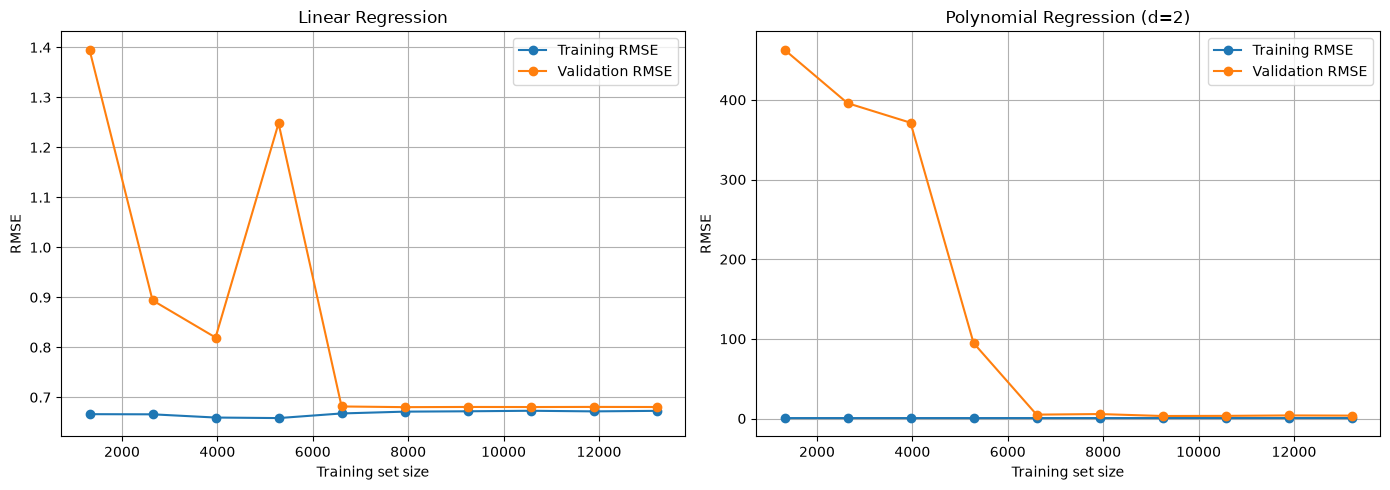

In [10]:
# Plot learning curves for both Linear and Polynomial models
train_sizes = np.linspace(0.1, 1.0, 10)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for model, name, ax in [
    (LinearRegression(), 'Linear Regression', axes[0]),
    (poly_pipeline, 'Polynomial Regression (d=2)', axes[1]),
]:
    sizes, train_scores, validation_scores = learning_curve(
        model, X_train_prepared, y_train, cv=5,
        train_sizes=train_sizes, scoring='neg_root_mean_squared_error'
    )
    train_rmse = -train_scores.mean(axis=1)
    validation_rmse = -validation_scores.mean(axis=1)
    ax.plot(sizes, train_rmse, 'o-', label='Training RMSE')
    ax.plot(sizes, validation_rmse, 'o-', label='Validation RMSE')
    ax.set_title(name)
    ax.set_xlabel('Training set size')
    ax.set_ylabel('RMSE')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.savefig('learning_curves.png', dpi=120)
plt.show()

**What do the learning curves tell you about bias vs. variance for each model? (4 pts)**

The Linear Regression training and validation curves converge near the same RMSE, which indicates relatively high bias and underfitting. The Polynomial Regression model has a lower training error, but its validation error is extremely high with smaller training sets and decreases as more data is added, which indicates high variance and unstable generalization with limited data.

**4.3 Regularized Models & Hyperparameter Tuning**

In [11]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV

# Train Ridge and Lasso with default parameters
ridge = Ridge()
lasso = Lasso()
ridge.fit(X_train_prepared, y_train)
lasso.fit(X_train_prepared, y_train)
evaluate_model(lasso, X_train_prepared, y_train, X_test_prepared, y_test, 'Lasso')

# Use GridSearchCV to find the best alpha for Ridge
param_grid = {'alpha': [0.01, 0.1, 1, 10, 100]}
grid_search = GridSearchCV(Ridge(), param_grid, cv=5, scoring='neg_root_mean_squared_error')
grid_search.fit(X_train_prepared, y_train)
print('Best alpha:', grid_search.best_params_)
print('Best CV RMSE:', -grid_search.best_score_)

best_ridge = grid_search.best_estimator_
evaluate_model(best_ridge, X_train_prepared, y_train, X_test_prepared, y_test, 'Ridge (tuned)')


--- Lasso ---
Train RMSE: 1.1570
Test  RMSE: 1.1417
Train MAE:  0.9130
Test  MAE:  0.9081
Train R²:   0.0000
Test  R²:   -0.0000
Best alpha: {'alpha': 100}
Best CV RMSE: 0.6798420992094

--- Ridge (tuned) ---
Train RMSE: 0.6740
Test  RMSE: 0.6585
Train MAE:  0.4848
Test  MAE:  0.4816
Train R²:   0.6606
Test  R²:   0.6673


Fill in the comparison table below. (5 pts)

In [12]:
comparison_table = pd.DataFrame(model_results).T.loc[[
    'Linear Regression',
    'SGD Regressor',
    'Polynomial (d=2)',
    'Ridge (tuned)',
    'Lasso',
], ['Train RMSE', 'Test RMSE', 'Train R²', 'Test R²']]
comparison_table.round(4)

,Train RMSE,Test RMSE,Train R²,Test R²
Linear Regression,0.6734,0.6579,0.6612,0.6679
SGD Regressor,0.6777,0.6579,0.6569,0.6679
Polynomial (d=2),0.6034,0.6034,0.7280,0.7206
Ridge (tuned),0.6740,0.6585,0.6606,0.6673
Lasso,1.1570,1.1417,0.0000,-0.0000


**Which model performs best and why? (3 pts)**

The Polynomial Regression model performs best because it has the lowest test RMSE (0.6034) and the highest test R² (0.7206). Its training and test metrics are also very close, indicating good performance on the held-out test set.

# PART 5 — Classification Models (20 pts)

Convert the regression problem into a binary classification task: predict whether a house is "expensive" (`MedHouseVal ≥ 2.5`) or "affordable" (`MedHouseVal < 2.5`).

In [13]:
# Create binary labels
y_train_bin = (y_train >= 2.5).astype(int)
y_test_bin  = (y_test  >= 2.5).astype(int)

print('Class distribution (train):')
print(y_train_bin.value_counts(normalize=True))

Class distribution (train):
MedHouseVal
0    0.719295
1    0.280705
Name: proportion, dtype: float64


**Answers:**

The training set contains approximately 28.07% expensive houses and 71.93% affordable houses, a ratio of about 1 expensive house to 2.56 affordable houses. The classes are moderately imbalanced because affordable houses form a clear majority.

This imbalance means that precision, recall, and AUC-ROC should be considered together with accuracy. Accuracy can be misleading because a model that mostly predicts the majority affordable class may achieve a high accuracy while failing to identify expensive houses.

**5.1 K-Nearest Neighbors & Naive Bayes**

In [14]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.metrics import accuracy_score, precision_score, recall_score

classifier_results = {}

def store_classifier_results(name, model, X_te=X_test_prepared):
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]
    classifier_results[name] = {
        'Accuracy': accuracy_score(y_test_bin, y_pred),
        'Precision': precision_score(y_test_bin, y_pred),
        'Recall': recall_score(y_test_bin, y_pred),
        'AUC-ROC': roc_auc_score(y_test_bin, y_prob),
    }
    return y_pred, y_prob

# Train KNN with k=5 and evaluate
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_prepared, y_train_bin)

# Train Gaussian Naive Bayes and evaluate
gnb = GaussianNB()
gnb.fit(X_train_prepared, y_train_bin)

for model, name in [(knn, 'KNN (k=5)'), (gnb, 'Naive Bayes')]:
    y_pred, y_prob = store_classifier_results(name, model)
    print(f'\n=== {name} ===')
    print(classification_report(y_test_bin, y_pred))
    print('AUC-ROC:', roc_auc_score(y_test_bin, y_prob))


=== KNN (k=5) ===
              precision    recall  f1-score   support

           0       0.88      0.94      0.91      2934
           1       0.82      0.70      0.76      1194

    accuracy                           0.87      4128
   macro avg       0.85      0.82      0.83      4128
weighted avg       0.87      0.87      0.87      4128

AUC-ROC: 0.907232995242059

=== Naive Bayes ===
              precision    recall  f1-score   support

           0       0.85      0.87      0.86      2934
           1       0.66      0.63      0.65      1194

    accuracy                           0.80      4128
   macro avg       0.76      0.75      0.75      4128
weighted avg       0.80      0.80      0.80      4128

AUC-ROC: 0.8336036579169421


Find the optimal k for KNN using cross-validation (`k = 1` to `20`). Plot accuracy vs. k. (4 pts)

Optimal k: 15


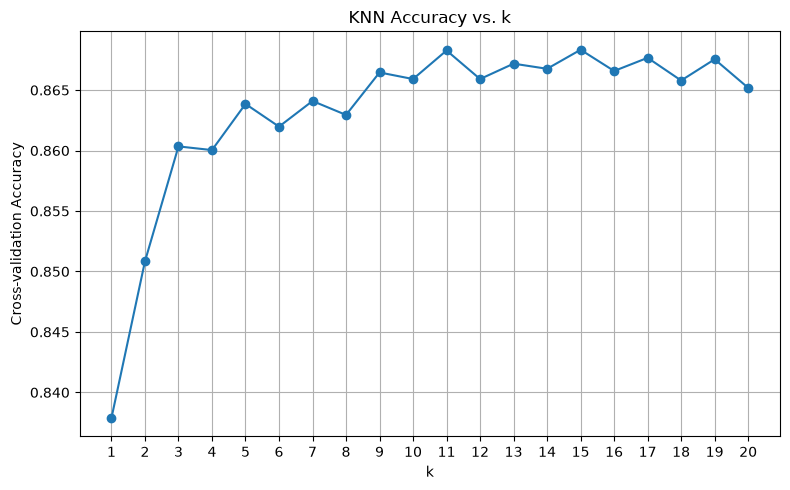

(array([1, 0, 0, ..., 1, 1, 0], shape=(4128,)),
 array([1.        , 0.46666667, 0.        , ..., 0.86666667, 0.53333333,
        0.26666667], shape=(4128,)))

In [15]:
from sklearn.model_selection import cross_val_score

k_values = range(1, 21)
cv_accuracies = []

for k in k_values:
    knn_cv = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn_cv, X_train_prepared, y_train_bin, cv=5, scoring='accuracy')
    cv_accuracies.append(scores.mean())

optimal_k = list(k_values)[int(np.argmax(cv_accuracies))]
print('Optimal k:', optimal_k)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), cv_accuracies, marker='o')
plt.xticks(list(k_values))
plt.xlabel('k')
plt.ylabel('Cross-validation Accuracy')
plt.title('KNN Accuracy vs. k')
plt.grid(True)
plt.tight_layout()
plt.savefig('knn_accuracy_vs_k.png', dpi=120)
plt.show()

knn_optimal = KNeighborsClassifier(n_neighbors=optimal_k)
knn_optimal.fit(X_train_prepared, y_train_bin)
store_classifier_results('KNN (optimal k)', knn_optimal)

**5.2 Decision Trees & Random Forests**

|--- MedInc <= 0.90
|   |--- AveOccup <= -0.06
|   |   |--- MedInc <= -0.39
|   |   |   |--- Latitude <= 1.06
|   |   |   |   |--- Longitude <= -1.36
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Longitude >  -1.36
|   |   |   |   |   |--- class: 0
|   |   |   |--- Latitude >  1.06
|   |   |   |   |--- bedrooms_ratio <= -0.56
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- bedrooms_ratio >  -0.56
|   |   |   |   |   |--- class: 0
|   |   |--- MedInc >  -0.39
|   |   |   |--- HouseAge <= -0.73
|   |   |   |   |--- MedInc <= 0.17
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- MedInc >  0.17
|   |   |   |   |   |--- class: 0
|   |   |   |--- HouseAge >  -0.73
|   |   |   |   |--- Latitude <= 1.10
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Latitude >  1.10
|   |   |   |   |   |--- class: 0
|   |--- AveOccup >  -0.06
|   |   |--- MedInc <= 0.27
|   |   |   |--- Longitude <= -1.41
|   |   |   |   |--- Latitude <= 1.20
|   |   |   |   |   |--- class: 1
|   

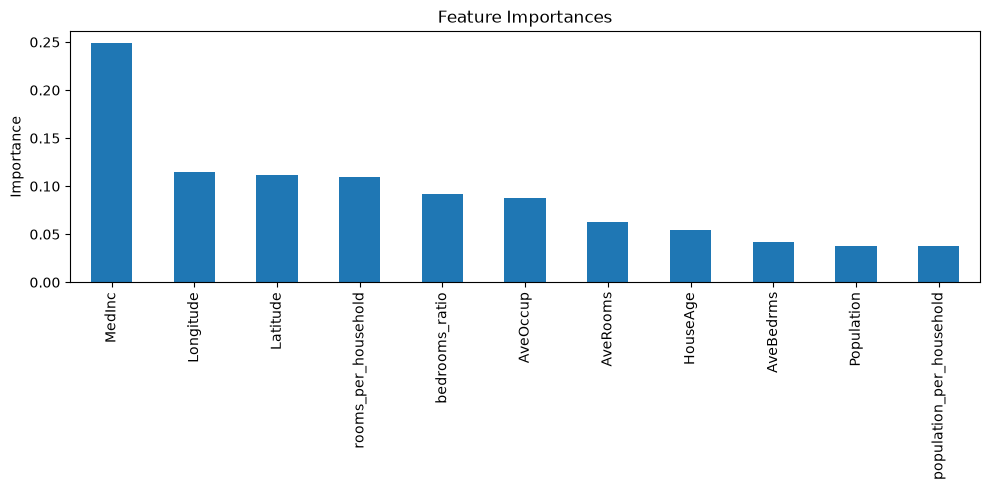

In [16]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier

# Train a Decision Tree with max_depth=5
dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train_prepared, y_train_bin)

# Print the tree structure
print(export_text(dt, feature_names=feature_cols))
store_classifier_results('Decision Tree', dt)

# Train a Random Forest with 100 trees
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_prepared, y_train_bin)
store_classifier_results('Random Forest', rf)

# Plot feature importance from Random Forest
importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
print(importances)
plt.figure(figsize=(10, 5))
importances.plot(kind='bar', title='Feature Importances')
plt.ylabel('Importance')
plt.tight_layout()
plt.savefig('feature_importances.png', dpi=120)
plt.show()

**Which features does the Random Forest consider most important? Does this align with your EDA findings in Part 2? (3 pts)**

The Random Forest considers `MedInc`, `Longitude`, and `Latitude` the most important features. This generally aligns with the EDA findings because `MedInc` had the strongest correlation with `MedHouseVal`, while the geographic variables showed that location also influences house values.

**5.3 Support Vector Machines**

In [17]:
from sklearn.svm import SVC

# Train SVM with RBF kernel
svm_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42)
svm_rbf.fit(X_train_prepared, y_train_bin)

# Train SVM with linear kernel
svm_lin = SVC(kernel='linear', C=1.0, probability=True, random_state=42)
svm_lin.fit(X_train_prepared, y_train_bin)

# Compare AUC-ROC for both kernels
for model, name in [(svm_rbf, 'SVM (RBF)'), (svm_lin, 'SVM (Linear)')]:
    y_pred, y_prob = store_classifier_results(name, model)
    print(f'{name} AUC-ROC: {roc_auc_score(y_test_bin, y_prob):.4f}')

d:\TháiMD\lab1_env\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
d:\TháiMD\lab1_env\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM (RBF) AUC-ROC: 0.9397
SVM (Linear) AUC-ROC: 0.9289


Complete the classifier comparison table below. (5 pts)

In [18]:
classifier_comparison = pd.DataFrame(classifier_results).T.loc[[
    'KNN (k=5)',
    'KNN (optimal k)',
    'Naive Bayes',
    'Decision Tree',
    'Random Forest',
    'SVM (RBF)',
    'SVM (Linear)',
]]
classifier_comparison.round(4)

,Accuracy,Precision,Recall,AUC-ROC
KNN (k=5),0.8697,0.8228,0.7002,0.9072
KNN (optimal k),0.8755,0.8534,0.6876,0.9295
Naive Bayes,0.8004,0.6620,0.6332,0.8336
Decision Tree,0.8602,0.8271,0.6533,0.8994
Random Forest,0.9070,0.8902,0.7739,0.9567
SVM (RBF),0.8852,0.8571,0.7236,0.9397
SVM (Linear),0.8697,0.8154,0.7102,0.9289


**Which classifier would you recommend for production use? Justify your choice considering both performance and computational cost. (3 pts)**

Random Forest is recommended for production use because it provides strong accuracy, precision, recall, and AUC-ROC while supporting efficient prediction after training. It is also less computationally expensive to use than an RBF SVM on a growing dataset and provides interpretable feature importance values.

# PART 6 — Report & Interpretation (10 pts)

**Executive Summary**

**Dataset and challenges.** The California Housing dataset contains 20,640 observations, eight numerical input features, and the continuous target MedHouseVal. It has no missing values, but it presents several challenges: the target is capped at approximately 5.0, the data were collected in the 1990s, and the features do not include categorical housing information. For classification, the data are also moderately imbalanced, with 71.93% affordable houses and 28.07% expensive houses.

**Preprocessing.** The stratified train/test split preserved the income distribution and produced more representative evaluation sets. Standardization had the greatest practical impact because KNN, SGD, and SVM depend on feature scale, while the engineered ratios added information about living space, bedroom share, and population conditions.

**Model results.** Polynomial Regression with degree 2 was the best regression model. It achieved a test RMSE of 0.6034, test MAE of 0.4274, and test R² of 0.7206. Because MedHouseVal is measured in units of \$100,000, its RMSE corresponds to approximately \$60,340, although individual prediction errors may be larger or smaller. Random Forest was the best classification model, with 90.70% accuracy, 89.02% precision, 77.39% recall, and an AUC-ROC of 0.9567. It is suitable for this task because it combines strong predictive performance with efficient prediction and interpretable feature importance.

**Recommendations.** First, future work should use newer housing data with additional categorical and neighborhood features. Second, model performance could be improved through broader hyperparameter tuning and cross-validated testing of stronger ensemble models.